# CSET485 Assignment 1 - Adult Census Income
   Yuvraj Garg | Roll no. S24BCAU0058 -> Adult Income dataset, `random_state = 58`, 70/30 split.

   Run all cells top to bottom (Runtime > Run all). The dataset downloads from UCI automatically.


In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
import statsmodels.api as sm
from scipy.stats import norm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

SEED = 58
cols = ["age","workclass","fnlwgt","education","education-num","marital-status","occupation",
        "relationship","race","sex","capital-gain","capital-loss","hours-per-week","native-country","income"]
SRC = os.environ.get("ADULT_PATH", "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data")
raw = pd.read_csv(SRC, names=cols, skipinitialspace=True, na_values="?")
print("shape:", raw.shape)
print("missing values per column:"); print(raw.isna().sum()[raw.isna().sum() > 0])

shape: (32561, 15)
missing values per column:
workclass         1836
occupation        1843
native-country     583
dtype: int64


## Data preprocessing

In [2]:
df = raw.copy()

# 1) Missing values: '?' only appears in 3 categorical columns -> keep as its own "Unknown" category
for c in ["workclass", "occupation", "native-country"]:
    df[c] = df[c].fillna("Unknown")

# 2) Simplify native-country (41 levels, ~90% US) to US / Non-US / Unknown to avoid sparse dummies
df["native-country"] = np.where(df["native-country"] == "United-States", "US",
                         np.where(df["native-country"] == "Unknown", "Unknown", "Non-US"))

# 3) Drop fnlwgt (survey sampling weight, not a person attribute) and education (duplicate of education-num)
df = df.drop(columns=["fnlwgt", "education"])

# 4) Target
df["income_bin"] = (df["income"].str.strip() == ">50K").astype(int)
print("base rate P(income>50K):", round(df["income_bin"].mean(), 4))

# 5) Outliers
print(df[["age", "capital-gain", "capital-loss", "hours-per-week"]].describe().round(1))
print("capital-gain == 99999 (top-coded):", (df["capital-gain"] == 99999).sum())
for c in ["capital-gain", "capital-loss"]:          # extremely skewed -> log1p
    df[c] = np.log1p(df[c])
for c in ["age", "hours-per-week"]:                 # winsorise at 1st / 99th percentile
    lo, hi = df[c].quantile([0.01, 0.99]); df[c] = df[c].clip(lo, hi)

# keep unscaled demographics for subgroup analysis
meta = df[["sex", "race", "age"]].copy()

# 6) Categorical encoding: one-hot, drop_first
cat_cols = ["workclass", "marital-status", "occupation", "relationship", "race", "sex", "native-country"]
X = pd.get_dummies(df.drop(columns=["income", "income_bin"]), columns=cat_cols, drop_first=True, dtype=float)
y = df["income_bin"]

# 7) Split 70/30 with seed 58
Xtr, Xte, ytr, yte, mtr, mte = train_test_split(X, y, meta, test_size=0.3, random_state=SEED)

# 8) Scaling: StandardScaler fitted on TRAIN only
num = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
sc = StandardScaler().fit(Xtr[num])
Xtr = Xtr.copy(); Xte = Xte.copy()
Xtr[num] = sc.transform(Xtr[num]); Xte[num] = sc.transform(Xte[num])
print("train/test:", Xtr.shape, Xte.shape, "| features:", X.shape[1])

base rate P(income>50K): 0.2408
           age  capital-gain  capital-loss  hours-per-week
count  32561.0       32561.0       32561.0         32561.0
mean      38.6        1077.6          87.3            40.4
std       13.6        7385.3         403.0            12.3
min       17.0           0.0           0.0             1.0
25%       28.0           0.0           0.0            40.0
50%       37.0           0.0           0.0            40.0
75%       48.0           0.0           0.0            45.0
max       90.0       99999.0        4356.0            99.0
capital-gain == 99999 (top-coded): 159
train/test: (22792, 45) (9769, 45) | features: 45


## Part 1 - Build and compare

In [3]:
Xtr_c = sm.add_constant(Xtr, has_constant="add"); Xte_c = sm.add_constant(Xte, has_constant="add")

ols = sm.OLS(ytr, Xtr_c).fit()                     # Model A
p_lin = ols.predict(Xte_c)
med = p_lin.median()
hiA = (p_lin >= med).astype(int)

logit = sm.Logit(ytr, Xtr_c).fit(disp=0, maxiter=200)   # Model B
p_log = logit.predict(Xte_c)
hiB = (p_log >= 0.5).astype(int)

cm = pd.crosstab(hiA.rename("OLS (>= median)"), hiB.rename("Logit (>= 0.5)"), margins=True)
mism = int((hiA != hiB).sum()); n = len(yte)
print("OLS median predicted value:", round(med, 4), "| logistic cutoff: 0.5")
print("OLS predictions < 0:", int((p_lin < 0).sum()), " > 1:", int((p_lin > 1).sum()))
print("Flagged high risk -> OLS:", int(hiA.sum()), f"({hiA.mean():.1%})", "| Logit:", int(hiB.sum()), f"({hiB.mean():.1%})")
print("Test base rate:", round(yte.mean(), 4))
print("Accuracy of Logit@0.5:", round(((hiB == yte).mean()), 4), "| OLS@median:", round(((hiA == yte).mean()), 4))
print(cm)
print(f"Mismatched: {mism} of {n} = {mism/n:.2%}")

OLS median predicted value: 0.219 | logistic cutoff: 0.5
OLS predictions < 0: 2187  > 1: 36
Flagged high risk -> OLS: 4885 (50.0%) | Logit: 1922 (19.7%)
Test base rate: 0.2477
Accuracy of Logit@0.5: 0.8393 | OLS@median: 0.7151
Logit (>= 0.5)      0     1   All
OLS (>= median)                  
0                4883     1  4884
1                2964  1921  4885
All              7847  1922  9769
Mismatched: 2965 of 9769 = 30.35%


## 2.1 Simpson's paradox hunt (subgroup effects)

In [4]:
def fit_logit(Xs, ys):
    Xs = Xs.loc[:, Xs.std() > 0]                    # drop columns constant inside the subgroup
    return sm.Logit(ys, sm.add_constant(Xs, has_constant="add")).fit(disp=0, maxiter=200)

key = ["age", "education-num", "hours-per-week", "capital-gain"]
splits = {
    "sex":  (mtr["sex"] == "Female",      "Female",  "Male"),
    "race": (mtr["race"] == "White",      "White",   "Non-White"),
    "age":  (mtr["age"] < 40,             "age<40",  "age>=40"),
}
full_m = fit_logit(Xtr, ytr)
hunt = []
for var, (mask, nA, nB) in splits.items():
    mA = fit_logit(Xtr[mask], ytr[mask]); mB = fit_logit(Xtr[~mask], ytr[~mask])
    for k in key:
        if k not in mA.params or k not in mB.params: continue
        bA, bB = mA.params[k], mB.params[k]; sA, sB = mA.bse[k], mB.bse[k]
        z = (bA - bB) / np.sqrt(sA**2 + sB**2)
        ciA, ciB = mA.conf_int().loc[k].values, mB.conf_int().loc[k].values
        hunt.append(dict(split=var, A=nA, B=nB, predictor=k, full=round(full_m.params[k], 3),
                         coef_A=round(bA, 3), ciA=np.round(ciA, 3), coef_B=round(bB, 3), ciB=np.round(ciB, 3),
                         sign_flip=bool(np.sign(bA) != np.sign(bB)), diff_p=round(2 * (1 - norm.cdf(abs(z))), 4)))
hunt = pd.DataFrame(hunt)
print(hunt.to_string())
print("\nSign flips vs full model:",
      hunt[(np.sign(hunt.coef_A) != np.sign(hunt.full)) | (np.sign(hunt.coef_B) != np.sign(hunt.full))][["split","predictor","full","coef_A","coef_B"]].to_string())

   split       A          B       predictor   full  coef_A             ciA  coef_B               ciB  sign_flip  diff_p
0    sex  Female       Male             age  0.400   0.451  [0.322, 0.579]   0.395    [0.338, 0.452]      False  0.4363
1    sex  Female       Male   education-num  0.747   0.901  [0.755, 1.047]   0.718     [0.66, 0.777]      False  0.0233
2    sex  Female       Male  hours-per-week  0.388   0.363  [0.252, 0.474]   0.398     [0.346, 0.45]      False  0.5723
3    sex  Female       Male    capital-gain  0.496   0.612  [0.531, 0.693]   0.463    [0.422, 0.505]      False  0.0013
4   race   White  Non-White             age  0.400   0.405  [0.358, 0.453]   0.344    [0.171, 0.516]      False  0.4986
5   race   White  Non-White   education-num  0.747   0.758    [0.7, 0.816]   0.668    [0.493, 0.843]      False  0.3379
6   race   White  Non-White  hours-per-week  0.388   0.385  [0.337, 0.434]   0.444    [0.285, 0.604]      False  0.4884
7   race   White  Non-White    capital-g

In [5]:
# Pick the row from the table above with a sign flip (or the smallest diff_p) and edit these two lines:
CHOSEN_SPLIT, CHOSEN_PRED = "sex", "education-num"
mask, nA, nB = splits[CHOSEN_SPLIT]
mA = fit_logit(Xtr[mask], ytr[mask]); mB = fit_logit(Xtr[~mask], ytr[~mask])
out = pd.DataFrame({"model": ["Full", nA, nB],
    "coef": [full_m.params[CHOSEN_PRED], mA.params[CHOSEN_PRED], mB.params[CHOSEN_PRED]],
    "ci_low": [full_m.conf_int().loc[CHOSEN_PRED, 0], mA.conf_int().loc[CHOSEN_PRED, 0], mB.conf_int().loc[CHOSEN_PRED, 0]],
    "ci_high": [full_m.conf_int().loc[CHOSEN_PRED, 1], mA.conf_int().loc[CHOSEN_PRED, 1], mB.conf_int().loc[CHOSEN_PRED, 1]],
    "p": [full_m.pvalues[CHOSEN_PRED], mA.pvalues[CHOSEN_PRED], mB.pvalues[CHOSEN_PRED]],
    "n": [len(ytr), int(mask.sum()), int((~mask).sum())]})
print(out.round(4).to_string(index=False))

 model   coef  ci_low  ci_high   p     n
  Full 0.7467  0.6923   0.8011 0.0 22792
Female 0.9008  0.7546   1.0469 0.0  7594
  Male 0.7185  0.6597   0.7772 0.0 15198


## 2.2 Omitted-variable bias

In [6]:
drop_cols = [c for c in Xtr.columns if c.startswith("marital-status_")]   # dropped confounder: marital status
red_m = sm.Logit(ytr, sm.add_constant(Xtr.drop(columns=drop_cols), has_constant="add")).fit(disp=0, maxiter=200)
preds = ["age", "education-num", "hours-per-week", "sex_Male", "capital-gain", "capital-loss"]
ov = pd.DataFrame({"full": logit.params[preds], "reduced": red_m.params[preds]})
ov["pct_change"] = (ov["reduced"] - ov["full"]) / ov["full"].abs() * 100
print("Dropped:", drop_cols)
print(ov.round(4))
print("Largest shift:", ov["pct_change"].abs().idxmax(), round(ov["pct_change"].abs().max(), 1), "%")
print("Pseudo-R2 full vs reduced:", round(logit.prsquared, 4), round(red_m.prsquared, 4))

Dropped: ['marital-status_Married-AF-spouse', 'marital-status_Married-civ-spouse', 'marital-status_Married-spouse-absent', 'marital-status_Never-married', 'marital-status_Separated', 'marital-status_Widowed']
                  full  reduced  pct_change
age             0.4004   0.4234      5.7296
education-num   0.7467   0.7416     -0.6878
hours-per-week  0.3881   0.3935      1.4036
sex_Male        0.8753   0.8641     -1.2798
capital-gain    0.4958   0.4967      0.1967
capital-loss    0.2442   0.2435     -0.2841
Largest shift: age 5.7 %
Pseudo-R2 full vs reduced: 0.4088 0.4057


## 2.3 Adversarial subset

In [7]:
yt = yte.values; pl = p_log.values
fp = (pl >= 0.75) & (yt == 0); fn = (pl <= 0.25) & (yt == 1)
adv_mask = fp | fn
print(f"High-confidence wrong: {adv_mask.sum()} of {len(yt)} = {adv_mask.mean():.2%}  (FP: {fp.sum()}, FN: {fn.sum()})")

adv_idx = Xte.index[adv_mask]
samp = pd.Series(adv_idx).sample(min(50, len(adv_idx)), random_state=SEED).values
print("sample size:", len(samp))

demo = pd.DataFrame({
    "sample50": [mte.loc[samp, "age"].mean(), (mte.loc[samp, "sex"] == "Female").mean(), (mte.loc[samp, "race"] == "White").mean()],
    "full_test": [mte["age"].mean(), (mte["sex"] == "Female").mean(), (mte["race"] == "White").mean()]},
    index=["mean age", "share female", "share White"])
print(demo.round(3))

bin_cols = [c for c in Xte.columns if set(Xte[c].unique()) <= {0.0, 1.0}]
cmp_ = pd.DataFrame({"sample50": Xte.loc[samp, bin_cols].mean(), "test": Xte[bin_cols].mean()})
cmp_["diff"] = cmp_["sample50"] - cmp_["test"]
print("\nBinary traits most over/under-represented in the 50 rows:")
print(cmp_.reindex(cmp_["diff"].abs().sort_values(ascending=False).index).head(8).round(3))
print("\nNumeric features (standardised means):")
print(pd.DataFrame({"sample50": Xte.loc[samp, num].mean(), "test": Xte[num].mean()}).round(3))
print("\nLogit coefficients for reference:"); print(logit.params.sort_values().round(3).to_string())

High-confidence wrong: 569 of 9769 = 5.82%  (FP: 120, FN: 449)
sample size: 50
              sample50  full_test
mean age         43.56     38.482
share female      0.34      0.325
share White       0.94      0.851

Binary traits most over/under-represented in the 50 rows:
                                   sample50   test   diff
occupation_Prof-specialty              0.26  0.127  0.133
marital-status_Married-civ-spouse      0.58  0.463  0.117
relationship_Own-child                 0.04  0.155 -0.115
marital-status_Never-married           0.24  0.331 -0.091
race_White                             0.94  0.851  0.089
occupation_Transport-moving            0.14  0.052  0.088
occupation_Other-service               0.02  0.104 -0.084
workclass_Private                      0.62  0.697 -0.077

Numeric features (standardised means):
                sample50   test
age                0.372 -0.005
education-num      0.274 -0.020
capital-gain       0.033  0.009
capital-loss       0.344 -0.009
hour

## 2.4 Fairness trade-off (sensitive variable: sex; A = Female, B = Male)

   t    DP    EO    PP  accuracy  sel_A  sel_B
0.05 0.456 0.410 0.797     0.639  0.330  0.723
0.15 0.336 0.270 0.976     0.757  0.191  0.568
0.25 0.304 0.246 0.976     0.806  0.138  0.452
0.35 0.293 0.268 0.911     0.832  0.105  0.356
0.45 0.281 0.264 0.914     0.838  0.081  0.287
0.55 0.268 0.261 0.922     0.840  0.061  0.229
0.65 0.272 0.277 0.931     0.832  0.047  0.171
0.75 0.242 0.287 0.922     0.816  0.028  0.117
0.85 0.212 0.096 1.037     0.792  0.014  0.064
0.95 0.199 0.000 1.025     0.766  0.004  0.019


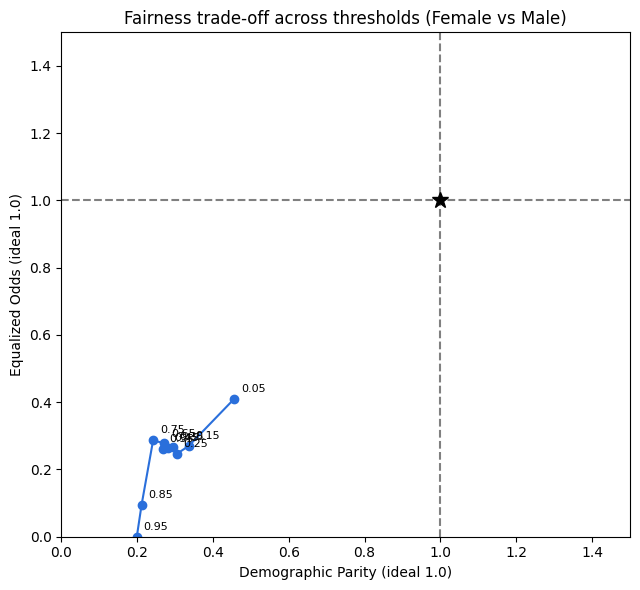

DP closest to 1 at t=0.05: DP=0.456, EO=0.410
EO closest to 1 at t=0.05: DP=0.456, EO=0.410
Moving t=0.05 -> t=0.05: DP gap closes 0.0%, EO gap changes 0.0%; cost ratio = nan


In [8]:
A = (mte["sex"] == "Female").values; B = ~A
def ratio(a, b): return a / b if (b is not None and b > 0 and not np.isnan(a) and not np.isnan(b)) else np.nan
def stats(g, yh):
    sel = yh[g].mean()
    tpr = yh[g & (yt == 1)].mean(); fpr = yh[g & (yt == 0)].mean()
    ppv = yt[g & (yh == 1)].mean() if (g & (yh == 1)).any() else np.nan
    return sel, tpr, fpr, ppv

rows = []
for t in np.round(np.arange(0.05, 0.96, 0.1), 2):
    yh = (pl >= t).astype(int)
    sA, tA, fA, pA = stats(A, yh); sB, tB, fB, pB = stats(B, yh)
    dp = ratio(sA, sB); eo = np.nanmin([ratio(tA, tB), ratio(fA, fB)]) if not (np.isnan(ratio(tA, tB)) and np.isnan(ratio(fA, fB))) else np.nan
    pp = ratio(pA, pB)
    rows.append(dict(t=t, sel_A=sA, sel_B=sB, TPR_A=tA, TPR_B=tB, FPR_A=fA, FPR_B=fB, PPV_A=pA, PPV_B=pB,
                     DP=dp, EO=eo, PP=pp, accuracy=(yh == yt).mean()))
fair = pd.DataFrame(rows)
print(fair[["t", "DP", "EO", "PP", "accuracy", "sel_A", "sel_B"]].round(3).to_string(index=False))
fair.round(4).to_csv("fairness_table.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(fair["DP"], fair["EO"], "-o", color="#2a6fdb")
for _, r in fair.iterrows():
    if not np.isnan(r.DP) and not np.isnan(r.EO): ax.annotate(f"{r.t:.2f}", (r.DP, r.EO), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.axvline(1, ls="--", c="grey"); ax.axhline(1, ls="--", c="grey"); ax.plot(1, 1, "k*", ms=12)
ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.5); ax.set_xlabel("Demographic Parity (ideal 1.0)"); ax.set_ylabel("Equalized Odds (ideal 1.0)")
ax.set_title("Fairness trade-off across thresholds (Female vs Male)"); plt.tight_layout(); plt.savefig("fairness_tradeoff.png", dpi=200); plt.show()

# quantify the trade-off between the DP-best and EO-best thresholds
f = fair.dropna(subset=["DP", "EO"])
t_dp = f.loc[(f.DP - 1).abs().idxmin()]; t_eo = f.loc[(f.EO - 1).abs().idxmin()]
print(f"DP closest to 1 at t={t_dp.t}: DP={t_dp.DP:.3f}, EO={t_dp.EO:.3f}")
print(f"EO closest to 1 at t={t_eo.t}: DP={t_eo.DP:.3f}, EO={t_eo.EO:.3f}")
dp_gain = (abs(1 - t_eo.DP) - abs(1 - t_dp.DP)) / abs(1 - t_eo.DP) * 100
eo_loss = (abs(1 - t_dp.EO) - abs(1 - t_eo.EO)) / abs(1 - t_eo.EO) * 100
print(f"Moving t={t_eo.t} -> t={t_dp.t}: DP gap closes {dp_gain:.1f}%, EO gap changes {eo_loss:.1f}%; cost ratio = {eo_loss/dp_gain if dp_gain else float('nan'):.2f}")

In [9]:
# 2.1 with age as the chosen split
mask, nA, nB = splits["age"]
mA = fit_logit(Xtr[mask], ytr[mask]); mB = fit_logit(Xtr[~mask], ytr[~mask])
rows = []
for nm, m in [("Full", full_m), (nA, mA), (nB, mB)]:
    ci = m.conf_int().loc["age"]
    rows.append((nm, m.params["age"], ci[0], ci[1], m.pvalues["age"], int(m.nobs)))
print(pd.DataFrame(rows, columns=["model","coef","ci_low","ci_high","p","n"]).round(4).to_string(index=False))

# 2.3 details
print("sample FP / FN:", int(pd.Series(fp, index=Xte.index)[samp].sum()), "/", int(pd.Series(fn, index=Xte.index)[samp].sum()))
r = raw.loc[Xte.index].copy(); r["p"] = pl; r["y"] = yt
def prof(d): return pd.Series({
    "n": len(d), "mean_p": d.p.mean(), "pct_age>=40": (d.age >= 40).mean(),
    "pct_married_civ": (d["marital-status"] == "Married-civ-spouse").mean(),
    "pct_prof_specialty": (d.occupation == "Prof-specialty").mean(),
    "pct_hours>40": (d["hours-per-week"] > 40).mean(),
    "pct_edu>=13": (d["education-num"] >= 13).mean(),
    "pct_cap_gain>0": (d["capital-gain"] > 0).mean(),
    "pct_White": (d.race == "White").mean()})
print(pd.DataFrame({"test_all": prof(r), "sample50": prof(r.loc[samp]), "all_FP": prof(r[fp]), "all_FN": prof(r[fn])}).round(3))

  model    coef  ci_low  ci_high      p     n
   Full  0.4004  0.3488   0.4520 0.0000 22792
 age<40  1.4242  1.2267   1.6218 0.0000 12815
age>=40 -0.1304 -0.2257  -0.0351 0.0073  9977
sample FP / FN: 10 / 40
                    test_all  sample50   all_FP   all_FN
n                   9769.000    50.000  120.000  449.000
mean_p                 0.238     0.288    0.832    0.141
pct_age>=40            0.436     0.620    0.758    0.530
pct_married_civ        0.463     0.580    0.975    0.492
pct_prof_specialty     0.127     0.260    0.358    0.140
pct_hours>40           0.292     0.520    0.567    0.372
pct_edu>=13            0.240     0.400    0.725    0.220
pct_cap_gain>0         0.085     0.080    0.367    0.062
pct_White              0.851     0.940    0.933    0.878


In [10]:
# ---- Derived numbers quoted in the report (Part 2.4 and Part 3) ----
f = fair.set_index("t")
def pct(new, old): return (new - old) / old * 100
a, b = 0.25, 0.05
dp_g, eo_g = pct(f.loc[b, "DP"], f.loc[a, "DP"]), pct(f.loc[b, "EO"], f.loc[a, "EO"])
pp_l, ac_l = pct(f.loc[b, "PP"], f.loc[a, "PP"]), pct(f.loc[b, "accuracy"], f.loc[a, "accuracy"])
print(f"t={a} -> t={b}: DP {dp_g:+.1f}%, EO {eo_g:+.1f}%, PP {pp_l:+.1f}%, accuracy {ac_l:+.1f}%")
print(f"trade-off cost = |PP loss| / DP gain = {abs(pp_l) / dp_g:.2f}")

print("always-predict-low-income accuracy:", round(1 - yte.mean(), 4),
      "| logistic gain over that (pts):", round(((hiB == yte).mean() - (1 - yte.mean())) * 100, 1))

age_mask = splits["age"][0]
mAa = fit_logit(Xtr[age_mask], ytr[age_mask]); mBa = fit_logit(Xtr[~age_mask], ytr[~age_mask])
print("age odds multiplier per SD  full / <40 / >=40:",
      round(np.exp(full_m.params["age"]), 2), round(np.exp(mAa.params["age"]), 2), round(np.exp(mBa.params["age"]), 2))
print("odds multipliers  sex_Male:", round(np.exp(logit.params["sex_Male"]), 2),
      "| Married-civ-spouse:", round(np.exp(logit.params["marital-status_Married-civ-spouse"]), 2),
      "| age (reduced model):", round(np.exp(red_m.params["age"]), 2))

lo = np.log(0.30 / 0.70)
print("two-applicant example: man p=0.30 -> woman p =", round(1 / (1 + np.exp(-(lo - logit.params["sex_Male"]))), 4))

rr = raw.loc[Xte.index]
h = rr["hours-per-week"] > 40; p0, p1 = h.mean(), h.loc[samp].mean()
print(f"hours>40: sample {p1:.3f} vs test {p0:.3f}, z = {(p1 - p0) / np.sqrt(p0 * (1 - p0) / len(samp)):.2f}")

t=0.25 -> t=0.05: DP +49.8%, EO +66.4%, PP -18.4%, accuracy -20.7%
trade-off cost = |PP loss| / DP gain = 0.37
always-predict-low-income accuracy: 0.7523 | logistic gain over that (pts): 8.7
age odds multiplier per SD  full / <40 / >=40: 1.49 4.15 0.88
odds multipliers  sex_Male: 2.4 | Married-civ-spouse: 8.98 | age (reduced model): 1.53
two-applicant example: man p=0.30 -> woman p = 0.1515
hours>40: sample 0.520 vs test 0.292, z = 3.54
